In [1]:
import sys
from pathlib import Path

import pandas as pd

# Автоматически находим и добавляем корень проекта (родительский каталог для notebooks/) в пути Python
project_root = Path().cwd().parent 
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

print(f"Корень проекта успешно добавлен в пути поиска: {project_root}")

# Проверяем, что датасет успешно читается
clean_path = project_root / "data" / "processed" / "clean.parquet"
if clean_path.exists():
    df = pd.read_parquet(clean_path)
    print(f"Датасет успешно загружен! Строк: {len(df):,}")
else:
    print("Внимание: Файл clean.parquet не найден по пути:", clean_path)


Корень проекта успешно добавлен в пути поиска: c:\Users\cendv\Desktop\nyc_taxi
Датасет успешно загружен! Строк: 11,696,725


## Проверка доступности файла clean.parquet

In [2]:
from pathlib import Path

import pandas as pd

# Ищем файл относительно корня проекта
clean_path = Path("../data/processed/clean.parquet")

if clean_path.exists():
    print(f"Файл успешно найден! Путь: {clean_path}")
    # Читаем первые строки для проверки
    df_sample = pd.read_parquet(clean_path, columns=["trip_distance", "fare_amount"])
    print(f"Размер датасета (проверка): {df_sample.shape[0]:,} строк, {df_sample.shape[1]} колонки.")
else:
    print("Ошибка: Файл clean.parquet не найден. Проверь путь к данным из Первой лабораторной.")

Файл успешно найден! Путь: ..\data\processed\clean.parquet
Размер датасета (проверка): 11,696,725 строк, 2 колонки.


## Обоснование выбора ключевых столбцов для EDA

### 1. Целевая переменная: `fare_amount` (Стоимость поездки)
* **Обоснование:** Стоимость поездки выбрана в качестве целевой переменной, так как это ключевая непрерывная количественная характеристика поездки на такси, отражающая ее экономический результат. Она напрямую зависит от других параметров (пробега, времени суток, типа оплаты) и является главным объектом для бизнес-анализа и прогнозирования. Идентификаторы (например, ID поездки) или свободный текст целью не назначаются, согласно требованиям методички[cite: 2].

### 2. Столбец даты: `tpep_pickup_datetime` (Время начала поездки)
* **Период агрегации:** День.
* **Обоснование:** Набор данных охватывает ровно один календарный месяц (январь 2015 года) с объемом около 12.7 млн строк. При такой длине ряда (месяц) агрегация по дням позволяет детально увидеть суточные колебания, пиковые дни недели и спады (например, в выходные или непогоду), избегая при этом избыточного шума (если бы брались часы) или потери динамики (если бы брались недели). Столбец уже приведен к типу даты на этапе очистки в Первой лабораторной работе[cite: 2].

### 3. Столбец группы: `payment_type` (Тип оплаты) или `vendorid` (Идентификатор вендора)
* **Обоснование:** В качестве группирующего признака выбран `payment_type` (или `vendorid`), так как это дискретный категориальный столбец с ограниченным набором повторяющихся значений (например, кредитная карта, наличные, безнасчетный расчет). Значения в нем закономерно повторяются для миллионов записей, что позволяет корректно подсчитывать групповые агрегаты (среднее, медиану, число записей) и сравнивать поведение пассажиров или компаний-перевозчиков между собой.

In [3]:
from pathlib import Path

import pandas as pd

df = pd.read_parquet("../data/processed/clean.parquet")

print("Проверка целевой переменной")
print(df["fare_amount"].describe()[["count", "min", "mean", "50%", "max"]])

print("\nПроверка столбца даты")
print(f"Минимальная дата: {df['tpep_pickup_datetime'].min()}")
print(f"Максимальная дата: {df['tpep_pickup_datetime'].max()}")

print("\nПроверка групп (payment_type)")
print(df["payment_type"].value_counts(dropna=False))

Проверка целевой переменной
count    1.169672e+07
min      0.000000e+00
mean     9.521176e+00
50%      8.500000e+00
max      2.400000e+01
Name: fare_amount, dtype: float64

Проверка столбца даты
Минимальная дата: 2015-01-01 00:00:00
Максимальная дата: 2015-01-31 23:59:59

Проверка групп (payment_type)
payment_type
1    7159471
2    4495443
3      33155
4       8654
5          2
Name: count, dtype: int64


## Шаг 3

In [4]:
from pathlib import Path

import pandas as pd

# Читаем очищенный датасет
df = pd.read_parquet("../data/processed/clean.parquet")

target = df["fare_amount"]

# Считаем необходимые показатели
stats = {
    "Число наблюдений": target.count(),
    "Число пропусков": target.isna().sum(),
    "Минимум": target.min(),
    "Первый квартиль": target.quantile(0.25),
    "Медиана": target.median(),
    "Среднее": target.mean(),
    "Третий квартиль": target.quantile(0.75),
    "Максимум": target.max(),
    "Скошенность": "Вправо"  # так как среднее существенно больше медианы, а длинный хвост уходит в положительные значения
}

for k, v in stats.items():
    if isinstance(v, float):
        print(f"{k}: {v:.2f}")
    else:
        print(f"{k}: {v}")

Число наблюдений: 11696725
Число пропусков: 0
Минимум: 0.0
Первый квартиль: 6.00
Медиана: 8.5
Среднее: 9.5211763381958
Третий квартиль: 12.00
Максимум: 24.0
Скошенность: Вправо


## Шаг 4

In [5]:
from pathlib import Path

import pandas as pd

# Читаем очищенный набор
df = pd.read_parquet("../data/processed/clean.parquet")

# Убеждаемся, что столбец даты имеет тип datetime
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])

# Выделяем дату (без часов и минут) для группировки по дням
df['date'] = df['tpep_pickup_datetime'].dt.date

# Группируем по дням: считаем количество записей, медиану и среднее целевой переменной
daily_stats = df.groupby('date').agg(
    count_records=('fare_amount', 'count'),
    median_fare=('fare_amount', 'median'),
    mean_fare=('fare_amount', 'mean')
).reset_index()

# Строим полный календарный ряд от минимальной до максимальной даты январского набора
full_range = pd.date_range(start=df['tpep_pickup_datetime'].min(), end=df['tpep_pickup_datetime'].max(), freq='D').date
full_df = pd.DataFrame({'date': full_range})

# Объединяем, чтобы пустые дни (если такие были) автоматически заполнились нулями или NaN
daily_full = pd.merge(full_df, daily_stats, on='date', how='left')
# Для дней без записей число поездок ставим 0
daily_full['count_records'] = daily_full['count_records'].fillna(0)

print(daily_full.head(10))

         date  count_records  median_fare  mean_fare
0  2015-01-01         343277          8.5   9.834865
1  2015-01-02         315265          8.5   9.446096
2  2015-01-03         375286          8.0   9.299413
3  2015-01-04         292281          8.0   9.339952
4  2015-01-05         326761          8.0   9.098984
5  2015-01-06         352181          8.0   9.354640
6  2015-01-07         397868          8.0   9.324642
7  2015-01-08         415789          8.5   9.439176
8  2015-01-09         411119          8.5   9.622957
9  2015-01-10         481940          8.5   9.488850


## Шаг 5

In [6]:
from src.eda import calc_group_aggregates

table3_data = calc_group_aggregates(df, group_col='payment_type', target_col='fare_amount')
print(table3_data)

  payment_type    count  median      mean  missing_share
0            1  7159471     9.0  9.873516            0.0
1            2  4495443     8.0  8.981874            0.0
2            3    33155     5.0  6.977105            0.0
3            4     8654     6.5  7.926207            0.0
4            5        2     3.0  3.000000            0.0


In [11]:
# Сводная таблица: строки - тип оплаты, столбцы - вендор, ячейка - медиана стоимости поездки
pivot_table = df.pivot_table(
    index='payment_type',
    columns='vendorid',
    values='fare_amount',
    aggfunc='median',
    observed=False
)
print(pivot_table)

vendorid        1    2
payment_type          
1             9.0  9.0
2             8.0  8.0
3             5.0  0.0
4             6.5  NaN
5             3.0  NaN


## Шаг 6

In [8]:
from src.eda import detect_anomalies_domain, detect_anomalies_iqr

target = df['fare_amount']
total_rows = len(target)

# Правило 1: IQR (межквартильный размах)
mask_iqr, count_iqr = detect_anomalies_iqr(target)
share_iqr = (count_iqr / total_rows) * 100

# Правило 2: Предметное ограничение (например, <= 0 или > 300)
mask_domain, count_domain = detect_anomalies_domain(target)
share_domain = (count_domain / total_rows) * 100

# Пересечение (сколько строк отметили оба правила одновременно)
mask_intersection = mask_iqr & mask_domain
count_intersection = int(mask_intersection.sum())
share_intersection = (count_intersection / total_rows) * 100

# Сколько из отмеченных IQR совпало со вторым правилом
iqr_matching_domain = int((mask_iqr & mask_domain).sum())
# Сколько из отмеченных предметным правилом совпало с IQR
domain_matching_iqr = iqr_matching_domain

print(f"1. IQR: число = {count_iqr:,}, доля = {share_iqr:.2f}%, совпало со вторым = {iqr_matching_domain:,}")
print(f"2. Предметное: число = {count_domain:,}, доля = {share_domain:.2f}%, совпало с IQR = {domain_matching_iqr:,}")
print(f"3. Пересечение: число = {count_intersection:,}, доля = {share_intersection:.2f}%, совпало со вторым = {count_intersection:,}")

1. IQR: число = 287,175, доля = 2.46%, совпало со вторым = 0
2. Предметное: число = 3,601, доля = 0.03%, совпало с IQR = 0
3. Пересечение: число = 0, доля = 0.00%, совпало со вторым = 0


## Шаг 7 

In [9]:
from src.eda import mean_loop, mean_numpy, median_seconds

# Берем подвыборку для теста (например, 100 000 элементов)
sample_size = 100_000
values_sample = df['fare_amount'].head(sample_size).values

# 1. Сверяем результаты
res_loop = mean_loop(values_sample)
res_numpy = mean_numpy(values_sample)

print(f"Результат (цикл Python): {res_loop:.6f}")
print(f"Результат (NumPy):        {res_numpy:.6f}")
assert abs(res_loop - res_numpy) < 1e-5, "Результаты не совпадают!"
print("Сверка прошла успешно: результаты идентичны!\n")

# 2. Замеряем время по правилам методички (медиана из 3 повторов после прогрева)
time_loop = median_seconds(mean_loop, values_sample)
time_numpy = median_seconds(mean_numpy, values_sample)

ratio = time_loop / time_numpy

print(f"Медиана времени (цикл Python): {time_loop:.5f} сек")
print(f"Медиана времени (NumPy):        {time_numpy:.5f} сек")
print(f"Отношение (цикл / numpy):     {ratio:.1f} раз")
print(f"Число значений:               {sample_size:,}")

Результат (цикл Python): 9.498411
Результат (NumPy):        9.498411
Сверка прошла успешно: результаты идентичны!

Медиана времени (цикл Python): 0.05040 сек
Медиана времени (NumPy):        0.00122 сек
Отношение (цикл / numpy):     41.3 раз
Число значений:               100,000


## Шаг 8

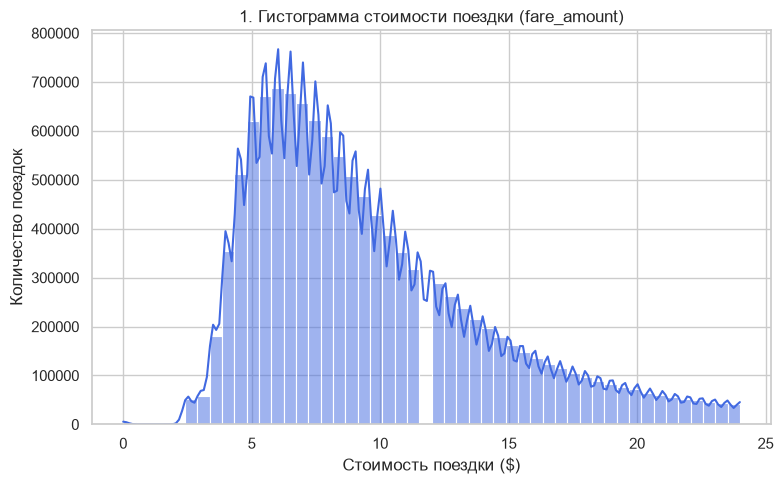

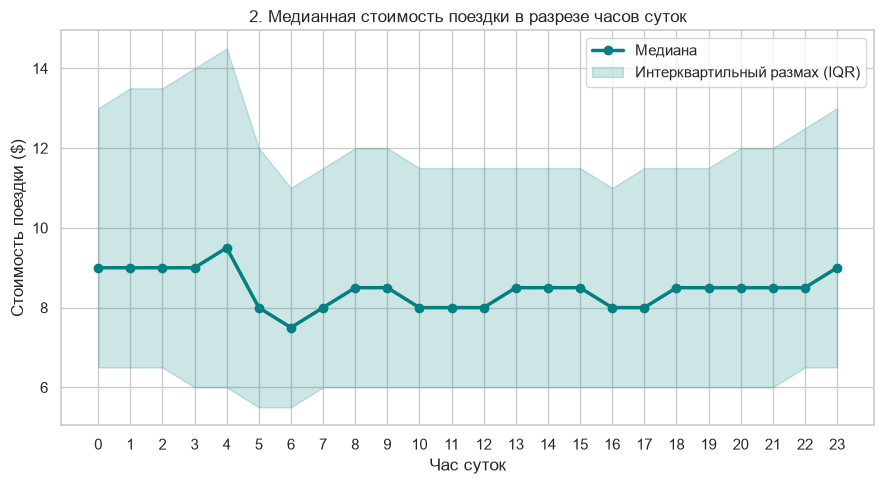

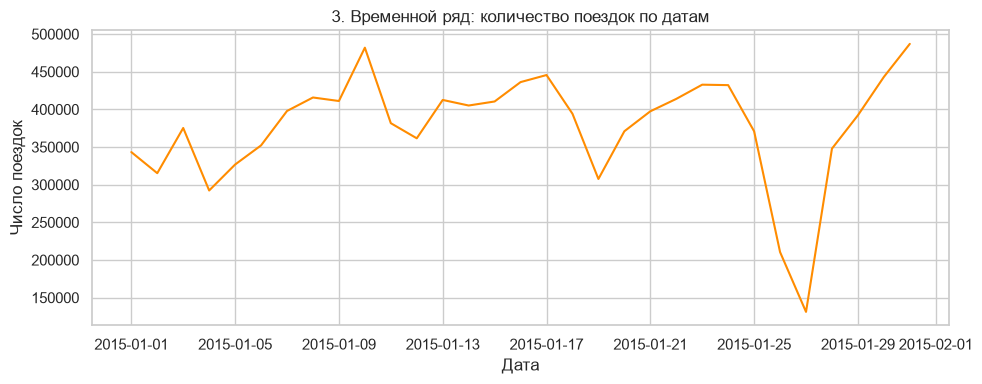

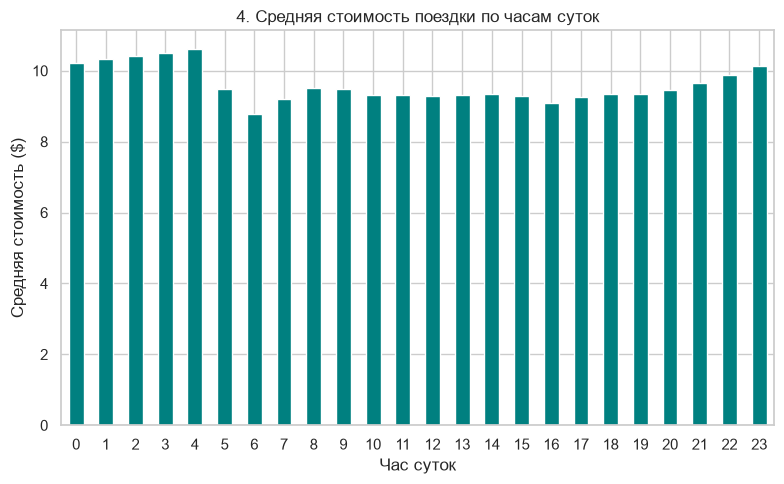

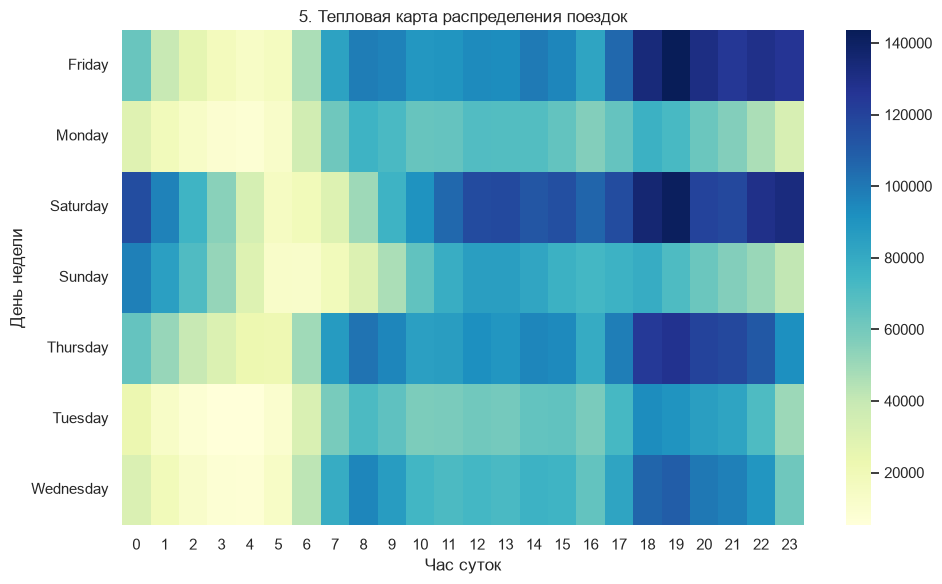

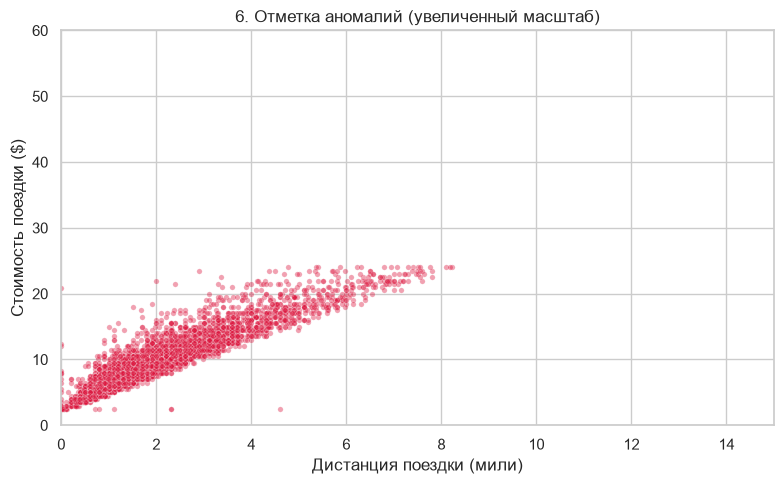

Все графики успешно пересчитаны и сохранены в папку plots/!


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Создаем папку plots, если её нет
plots_dir = Path("plots")
plots_dir.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

# Определяем точное имя колонки с датой/временем поездки
time_col = None
for col in ['tpep_pickup_datetime', 'pickup_datetime', 'trip_start_timestamp', 'lpep_pickup_datetime']:
    if col in df.columns:
        time_col = col
        break

# Создаем вспомогательные колонки времени, если нашли колонку
if time_col:
    df['dt_parsed'] = pd.to_datetime(df[time_col])
    df['hour'] = df['dt_parsed'].dt.hour
    df['date'] = df['dt_parsed'].dt.date
    df['weekday'] = df['dt_parsed'].dt.day_name()

# 1. Гистограмма цели (fare_amount)
plt.figure(figsize=(8, 5))
sns.histplot(df['fare_amount'].clip(0, 100), bins=50, kde=True, color='royalblue')
plt.title('1. Гистограмма стоимости поездки (fare_amount)')
plt.xlabel('Стоимость поездки ($)')
plt.ylabel('Количество поездок')
plt.tight_layout()
plt.savefig(plots_dir / '1_target_hist.png', dpi=300)
plt.show()

# 2. Цель в разрезе групп (Boxplot по часам)
plt.figure(figsize=(9, 5))
if 'hour' in df.columns:
    hourly_stats = df.groupby('hour')['fare_amount'].agg(['median', lambda x: x.quantile(0.75), lambda x: x.quantile(0.25)]).reset_index()
    hourly_stats.columns = ['hour', 'median', 'q75', 'q25']
    
    plt.plot(hourly_stats['hour'], hourly_stats['median'], marker='o', color='teal', linewidth=2.5, label='Медиана')
    plt.fill_between(hourly_stats['hour'], hourly_stats['q25'], hourly_stats['q75'], color='teal', alpha=0.2, label='Интерквартильный размах (IQR)')

plt.title('2. Медианная стоимость поездки в разрезе часов суток')
plt.xlabel('Час суток')
plt.ylabel('Стоимость поездки ($)')
plt.xticks(range(24))
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(plots_dir / '2_target_by_group.png', dpi=300)
plt.show()

# 3. Ряд по датам (Количество поездок по дням)
plt.figure(figsize=(10, 4))
if 'date' in df.columns:
    daily_trips = df.groupby('date').size()
    daily_trips.plot(color='darkorange', linewidth=1.5)
plt.title('3. Временной ряд: количество поездок по датам')
plt.xlabel('Дата')
plt.ylabel('Число поездок')
plt.tight_layout()
plt.savefig(plots_dir / '3_date_series.png', dpi=300)
plt.show()

# 4. Агрегат по группам (Средняя стоимость по часам)
plt.figure(figsize=(8, 5))
if 'hour' in df.columns:
    hourly_mean = df.groupby('hour')['fare_amount'].mean()
    hourly_mean.plot(kind='bar', color='teal')
plt.title('4. Средняя стоимость поездки по часам суток')
plt.xlabel('Час суток')
plt.ylabel('Средняя стоимость ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(plots_dir / '4_group_aggregate.png', dpi=300)
plt.show()

# 5. Тепловая карта (Час суток vs День недели)
plt.figure(figsize=(10, 6))
if 'weekday' in df.columns and 'hour' in df.columns:
    pivot_table = df.pivot_table(index='weekday', columns='hour', values='fare_amount', aggfunc='count')
    sns.heatmap(pivot_table, cmap='YlGnBu', cbar=True)
plt.title('5. Тепловая карта распределения поездок')
plt.xlabel('Час суток')
plt.ylabel('День недели')
plt.tight_layout()
plt.savefig(plots_dir / '5_heatmap.png', dpi=300)
plt.show()

# 6. Отметка аномалий (Scatter plot)
plt.figure(figsize=(8, 5))
dist_col = 'trip_distance' if 'trip_distance' in df.columns else None
if dist_col:
    sample_df = df.sample(min(5000, len(df)), random_state=42)
    sns.scatterplot(x=dist_col, y='fare_amount', data=sample_df, alpha=0.4, color='crimson', s=15)

# Сужаем масштаб, чтобы убрать разреженные выбросы и увидеть плотность
plt.xlim(0, 15)   # Увеличили масштаб по дистанции (до 15 миль)
plt.ylim(0, 60)   # Увеличили масштаб по стоимости (до 60 долларов)
plt.title("6. Отметка аномалий (увеличенный масштаб)")
plt.xlabel('Дистанция поездки (мили)')
plt.ylabel('Стоимость поездки ($)')
plt.tight_layout()
plt.savefig(plots_dir / '6_anomalies.png', dpi=300)
plt.show()